# My Question: 
# What is the mean and standard deviation of the total sum obtained when rolling 5 standard six-sided dice on an initial roll in Yahtzee?

# Description:
## Random variable(x) is the total sum of the 5 dice that are rolled at the same time. X can take any integer between 5 to 30 as discrete variables as the dice are all six-sided in Yahtzee. (1+1+1+1+1) = 5 and (6+6+6+6+6) = 30
## One trial would be the rolling of 5 six-sided dice at once and then the outcome would be the sum of those die. Possible outcomes would be between sums of 5 to 30. 

# Analysis:

In [27]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [28]:
num_trials = 10000  

In [29]:
dice_rolls = np.random.randint(1, 7, size=(num_trials, 5))

In [30]:
df = pd.DataFrame(
    dice_rolls, columns=["Die_1", "Die_2", "Die_3", "Die_4", "Die_5"]
)

In [31]:
df["sumx"] = df.sum(axis=1)

In [32]:
print("--- Sample Trials ---")
print(df.head())

--- Sample Trials ---
   Die_1  Die_2  Die_3  Die_4  Die_5  sumx
0      3      4      5      5      6    23
1      5      5      1      5      1    17
2      4      5      5      6      1    21
3      2      2      2      2      6    14
4      3      1      5      6      4    19


In [33]:
mean = df["sumx"].mean()

In [34]:
std = df["sumx"].std()

In [35]:
print("\n--- Simulation Results ---")


--- Simulation Results ---


In [36]:
print(f"mean of x: {mean:.2f}")

mean of x: 17.49


In [37]:
print(f"standard deviation of x: {std:.2f}")

standard deviation of x: 3.82


In [42]:
calcexpectedmean = (1+2+3+4+5+6)/6
finalexpecmean = calcexpectedmean * 5
print("Expected Mean:" , finalexpecmean)

Expected Mean: 17.5


## Theoretical Expected Value(Mean) : 17.5

In [49]:
variance_single_die = np.mean(
    [(k - calcexpectedmean) ** 2 for k in range(1, 7)]
)
theoretical_std = np.sqrt(5 * variance_single_die)

In [50]:
print(f"Theoretical Standard Deviation:  {theoretical_std:.4f}")

Theoretical Standard Deviation:  3.8188


## Theoretical Standard Deviation: 3.81

In [38]:
prob_dist = df["sumx"].value_counts(normalize=True).sort_index()

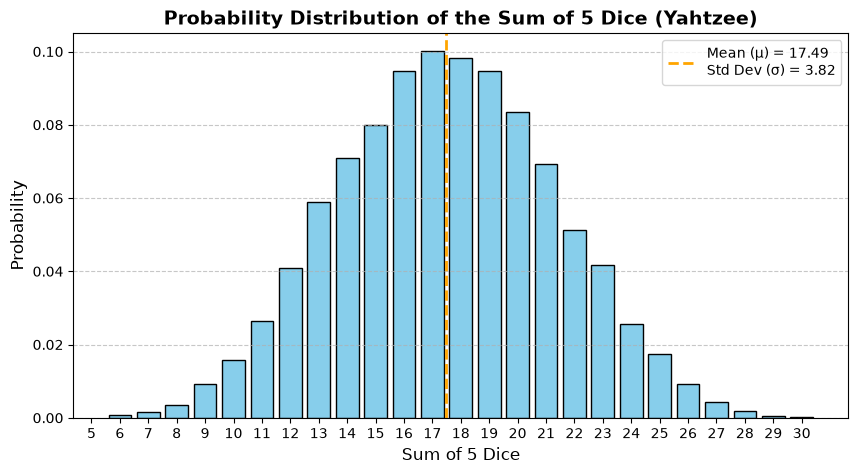

In [39]:
plt.figure(figsize=(10, 5))
plt.bar(
    prob_dist.index,
    prob_dist.values,
    color="skyblue",
    edgecolor="black",
    width=0.8,
)


plt.title(
    "Probability Distribution of the Sum of 5 Dice (Yahtzee)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Sum of 5 Dice", fontsize=12)
plt.ylabel("Probability", fontsize=12)
plt.xticks(range(5, 31))  
plt.grid(axis="y", linestyle="--", alpha=0.7)


plt.axvline(
    mean,
    color="orange",
    linestyle="dashed",
    linewidth=2,
   label=f"Mean (μ) = {mean:.2f}\nStd Dev (σ) = {std:.2f}",)

plt.legend()

plt.show()

# My Conclusion:
## When rolling 5 6-sided die for the first time in Yahtzee the *expected value for the mean* of the total sum is **17.5**. The *theoretical standard deviation* from the expected value is **3.81**. 
## The graph above represents the results of the simulation which created a symmeterical, bell distribution centered around the middle. 
## -This graph supports my answer as it shows that the empirical mean is 17.54 which is similar to the expected mean value of 17.5. 
## -It also shows a huge distribution explaining the standard deviation value of 3.82 due to the outliers at the ends of the bar graph. The standard deviation from the simulation, 3.82, matches the theoretical STD which is 3.81. This graph and simulation supports my calculations and answers.  